In [1]:
%reload_ext autoreload
%autoreload 2


from analysis.team_seasonranker import TeamAnalyzer as tmanalyzer
import constants.constants as constants
from visuals.animation_season import LeagueTableAnimation
import matplotlib.pyplot as plt
from IPython.display import HTML
import seaborn as sns
import numpy as np 
import visuals.pitch_visuals as pitchvisual
from analysis.team_statistics import TeamStatistics 
from logos.logo_loader import LogoManager
from data.build_datasets import build_dataset



In [2]:
'''
Load Soccer Data
1. Load fixtures data
2. Load player match data
3. Load players data
4. Load teams data
5. Load transfers data
'''

player_dataset = build_dataset()

player_match_names = player_dataset.player_match_names
transfers = player_dataset.cleaned_transfers
fixtures = player_dataset.fixtures
players_df = player_dataset.players
teams_df = player_dataset.teams
team_map = player_dataset.team_map
team_name_map = player_dataset.team_name_map

In [3]:
fixture_analysis = fixtures.copy()  # expects columns: home_team_shortname, away_team_shortname, home_score, away_score, gameweek
ranker = tmanalyzer(fixture_analysis)
table_ranking = ranker.rank_all_gameweeks()


team_colors = constants.TEAM_COLORS

In [4]:
sns.set_style('white')

animation = LeagueTableAnimation(fixture_analysis, team_colors)
fig, ani = animation.create_animation()

ani.save(
    "visuals/output/league_table_animation.gif",
    writer="pillow",
    fps=1
)

HTML(ani.to_jshtml())

In [5]:
# Set up constants for pitch visuals
primary_pitch_col = constants.PRIMARY_PITCH_COLS
primary_x_loc = constants.PRIMARY_X_LOC
TOP_Y = constants.TOP_Y
HEX_RADIUS = constants.HEX_RADIUS
pl_team_colors_25_26 = constants.TEAM_COLORS

# Load team logos
logos = LogoManager()
logos.load_logos()


In [6]:
teamstats = TeamStatistics(fixture_analysis)
team_offensive_data = teamstats.build_offensive_data()

In [7]:
team_season = team_offensive_data.groupby(['team_shortname', 'is_home']).sum().reset_index()
team_season.drop(columns=['opp_team_shortname', 'gameweek'], inplace=True)


In [8]:
season_table = table_ranking.copy()

max_gw = int(season_table.columns[-1].split('_')[1])
col = f'gmwk_{max_gw}_rank'

ranks_10 = (
    season_table
    .loc[season_table[col].lt(11), ['team', col]]
    .sort_values(col)
    ['team']
    .values
)

In [9]:
def draw_team_grid(
    teams,
    team_season,
    season_table,
    player_match_names,
    primary_x_loc,
    primary_pitch_col,
    top_y,
    hex_radius,
    figsize=(25, 20),
    ncols=3,
):
    """
    Draw a pitch visualization grid for a list of teams.
    """

    nrows = int(np.ceil(len(teams) / ncols))

    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    axs = np.atleast_1d(axs).ravel()
    axs_to_draw = [i for i in range(0, len(ranks_10)+1) if i not in [9,11]]

    for pos, team_short in zip(axs_to_draw, teams):

        ax = axs[pos]

        pitchvisual.draw_field(ax)
        artists = pitchvisual.create_team_artists(ax, primary_x_loc, primary_pitch_col, top_y, hex_radius)

        scoring_data = teamstats.team_scoring_data(team_short)
        team_data = team_season[team_season["team_shortname"] == team_short]

        pitchvisual.update_team_artists(ax, artists, scoring_data, team_data, team_short, season_table, player_match_names)
        logos.add_logo(ax, team_short, (62, 112), 0.04,)

    #
    # Hide extra axes
    #
    used = set(axs_to_draw)

    for idx, ax in enumerate(axs):
        if idx not in used:
            ax.axis('off')

    plt.subplots_adjust(wspace=-0.7, hspace=0)

    return 

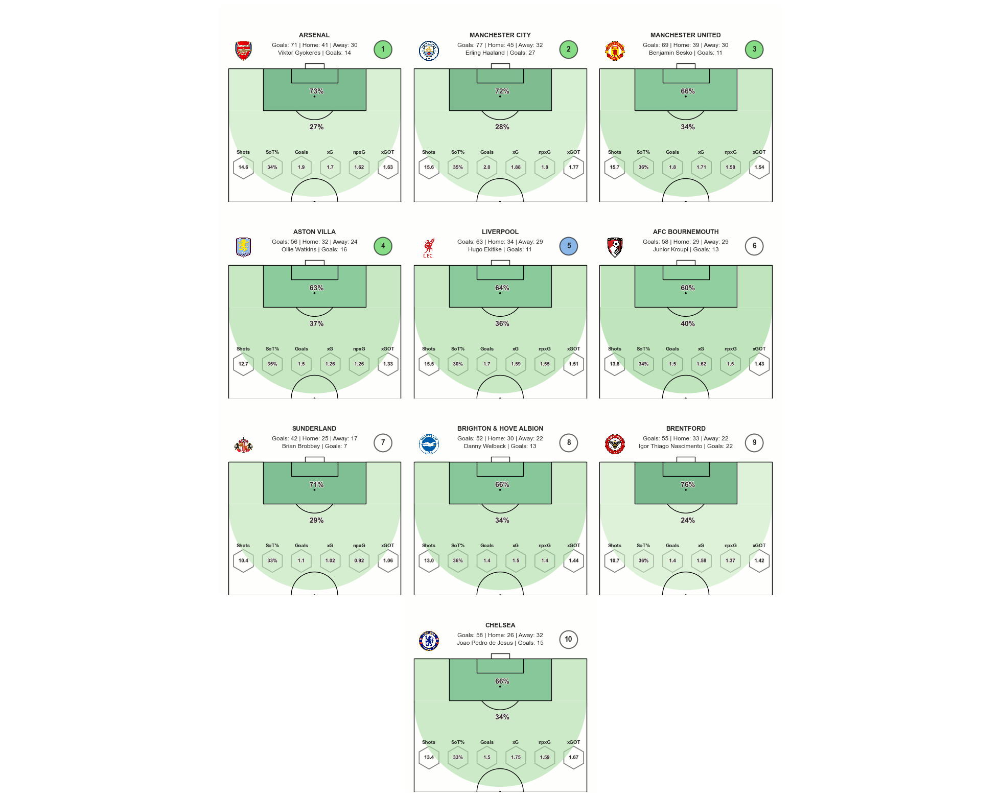

In [10]:
draw_team_grid(
    ranks_10,
    team_season,
    season_table,
    player_match_names,
    primary_x_loc,
    primary_pitch_col,
    TOP_Y,
    HEX_RADIUS,
)

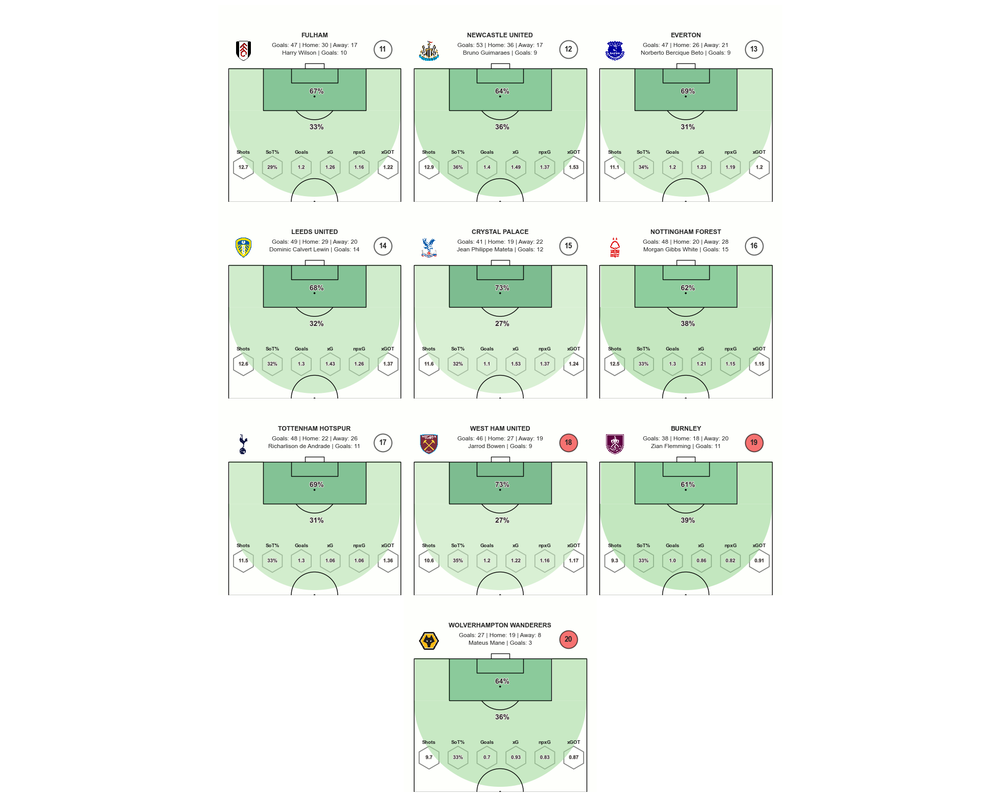

In [11]:
mask = season_table[col].between(11, 20, inclusive='both') & season_table[col].notna()
ranks_20 = season_table.loc[mask, ['team', col]].sort_values(col)['team'].values

draw_team_grid(
    ranks_20,
    team_season,
    season_table,
    player_match_names,
    primary_x_loc,
    primary_pitch_col,
    TOP_Y,
    HEX_RADIUS,
)

In [12]:
cols=team_offensive_data.columns[3:]
team_off_rev = team_offensive_data.groupby('team_shortname')[cols].sum().div(max_gw).round(2).reset_index()


In [13]:
DATA_IMAGE_POINTS = {'ARS': (1.70, 0.81),
 'AVL': (1.28, 1.34),
 'BHA': (1.501, 1.24),
 'BOU': (1.621, 1.43),
 'BRE': (1.581, 1.37),
 'BUR': (0.861, 1.94),
 'CHE': (1.751, 1.32),
 'CRY': (1.531, 1.33),
 'EVE': (1.25, 1.49),
 'FUL': (1.24, 1.34),
 'LEE': (1.43, 1.41),
 'LIV': (1.591, 1.20),
 'MCI': (1.88, 1.13),
 'MUN': (1.71, 1.21),
 'NEW': (1.49, 1.41),
 'NFO': (1.195, 1.51),
 'SUN': (1.021, 1.371),
 'TOT': (1.061, 1.30),
 'WHU': (1.22, 1.62),
 'WOL': (0.931, 1.49)}

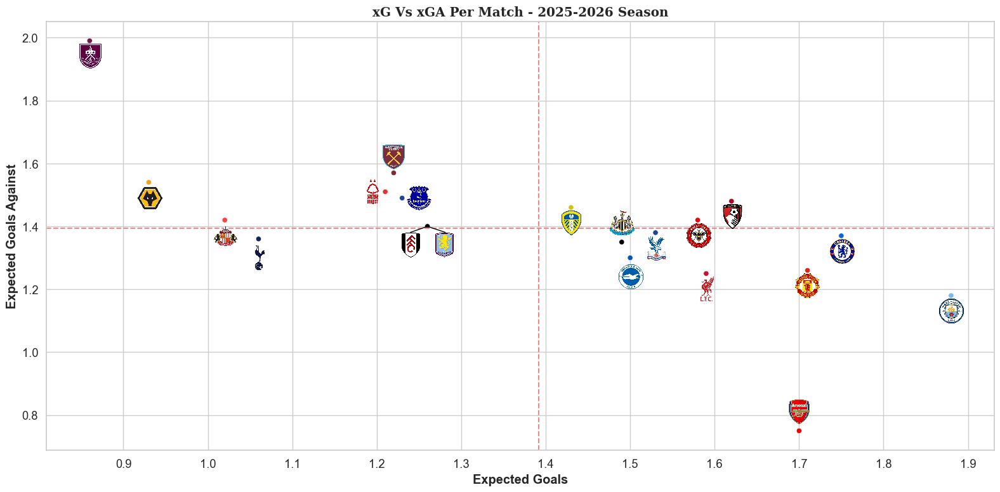

In [14]:
sns.set_context("notebook", font_scale=1.2)
sns.set_style('whitegrid')

fig, ax = plt.subplots(figsize=(16,8))

sns.scatterplot(x="expected_goals_xg", y="opp_expected_goals_xg", data=team_off_rev, hue= 'team_shortname', palette= pl_team_colors_25_26, ax= ax, legend= False)
plt.xticks(np.arange(.8, 2, step=.1))

plt.axvline(x =team_off_rev.expected_goals_xg.mean(), color = "#F08989", linestyle = '--', )
plt.axhline(y =team_off_rev.opp_expected_goals_xg.mean(), color = "#F08989", linestyle = '--')

line_segments = []

for team_short, value in DATA_IMAGE_POINTS.items():
    logos.add_logo(ax, team_short, value, zoom=.04)

    if team_short in ('AVL', 'FUL'):
        data_logo = value
        data_points = team_off_rev.loc[team_off_rev['team_shortname'] == team_short,['expected_goals_xg','opp_expected_goals_xg']].values[0].tolist()
            
        if team_short == 'AVL':
            end = (data_logo[0] + 0.001, data_logo[1] + 0.041)
        else:  # 'FUL'
            end = (data_logo[0], data_logo[1] + 0.041)

        # segment from data point to shortened logo position
        seg = [(end[0], data_points[0]), (end[1], data_points[1])]
        line_segments.append(seg)


# --- draw all special lines in one loop (still cheap) ---
for x_pair, y_pair in line_segments:
    ax.plot(x_pair, y_pair, color='black', linewidth=1, linestyle='-', zorder=10)

ax.set_title("xG Vs xGA Per Match - 2025-2026 Season", fontsize=18, font="serif", weight="bold")
ax.set_xlabel("Expected Goals", weight="bold")
ax.set_ylabel("Expected Goals Against", weight="bold")

fig.tight_layout()
plt.show()

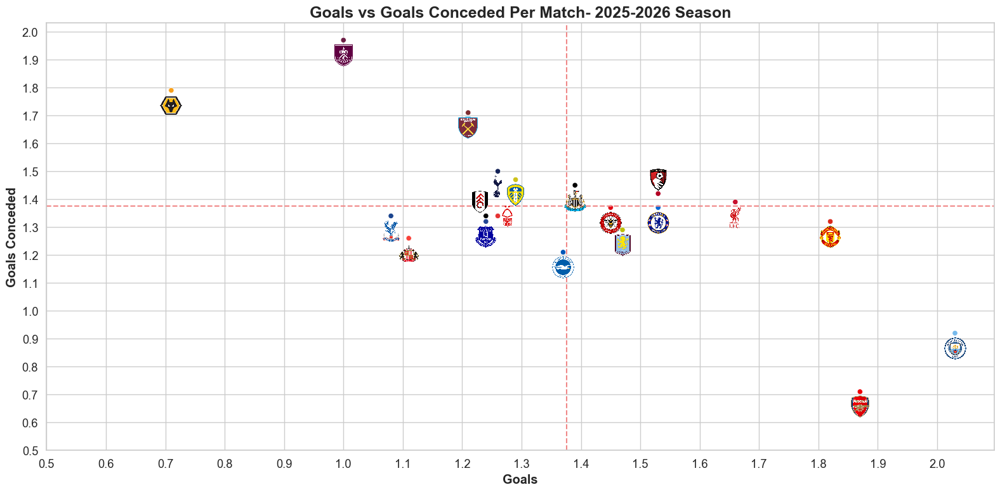

In [15]:
fig, ax = plt.subplots(figsize=(16,8))

sns.scatterplot(x="score", y="opp_score", data=team_off_rev, hue= 'team_shortname', palette= pl_team_colors_25_26, ax= ax, legend= False)
plt.xticks(np.arange(.5, 2.1, step=.1))
plt.yticks(np.arange(.5, 2.1, step=.1))

plt.axvline(x =team_off_rev.score.mean(), color = "#F08989", linestyle = '--', )
plt.axhline(y =team_off_rev.opp_score.mean(), color = "#F08989", linestyle = '--')

coords = team_off_rev.set_index("team_shortname")[["score", "opp_score"]]
xy_map = {k: (v["score"], v["opp_score"]) for k, v in coords.to_dict("index").items()}

offsets = {
    "FUL": (-0.01, 0.05),
    "NFO": (0.016, 0.0),
    "BOU": (0.0, 0.05),
}
default_offset = (0.0, -0.055)

for team, (x, y) in xy_map.items():
    dx, dy = offsets.get(team, default_offset)
    logo_pos = (x + dx, y + dy)
    logos.add_logo(ax, team, logo_pos, zoom=0.035)

ax.set_xlabel("Goals", weight = 'bold')
ax.set_ylabel("Goals Conceded", weight = 'bold')
ax.set_title("Goals vs Goals Conceded Per Match- 2025-2026 Season", fontsize=18, weight = 'bold')
fig.tight_layout()
plt.show()

In [16]:
team_deff_data = teamstats.build_defensive_data()


In [17]:
contrib_cols = team_deff_data.columns[3:7] 
data_def_grp = team_deff_data.groupby('team_shortname')[contrib_cols].sum().div(max_gw).round(2)


In [18]:
data_def_grp['sum_def_cont'] = data_def_grp.sum(axis=1).round(1)
data_sorted = data_def_grp.sort_values('sum_def_cont')


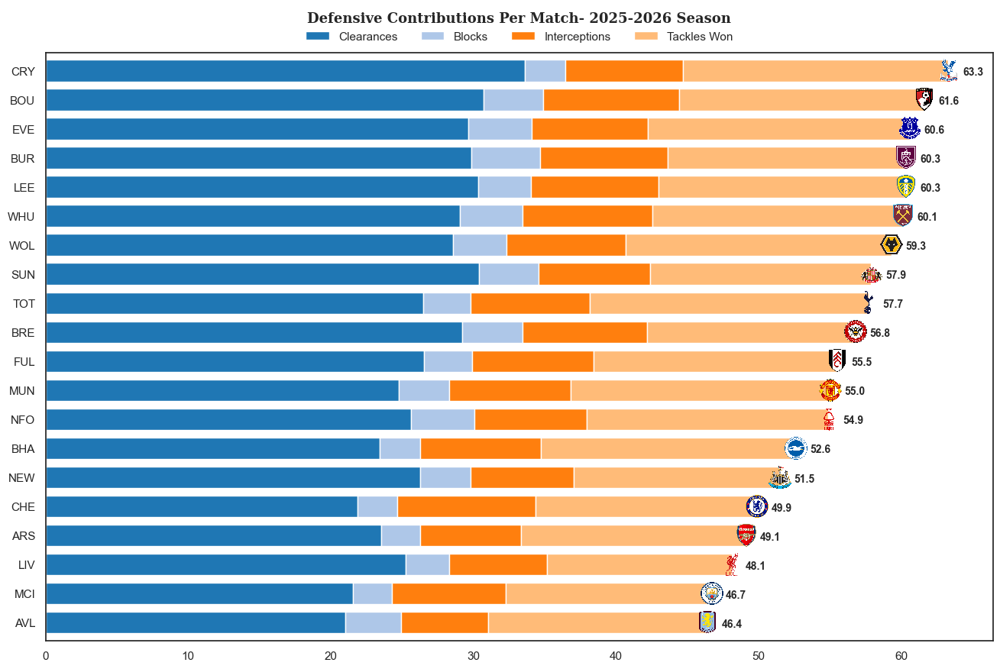

In [19]:
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(16, 10))

plot_df = data_sorted[contrib_cols]   
plot_df.plot(kind='barh', stacked=True, ax=ax, width=0.75, color=sns.color_palette('tab20'))

ax.set_yticklabels(plot_df.index.values)
ax.set_ylabel('')

ends = data_sorted['sum_def_cont'].values 
y_positions = np.arange(len(plot_df))

for y, team, x_end in zip(y_positions, plot_df.index, ends):
  logos.add_logo(ax, team, (x_end,y), zoom = .03)
  ax.text(x_end + 1, y - 0.05, str(x_end), fontsize=10, weight='bold', va='center')

ax.legend(labels = ['Clearances', 'Blocks','Interceptions','Tackles Won'], loc = 'lower center', 
          bbox_to_anchor = (.5,1), ncol = 5, title = 'Defensive Contributions Per Match- 2025-2026 Season', 
          title_fontproperties = {'family': 'serif', 'weight': 'bold', 'size': 13, 'stretch': 'expanded'},  frameon = False)


plt.show()


In [20]:
possession= team_deff_data.groupby('team_shortname')['possession'].mean().round(2).reset_index()
df_poss = possession.merge(data_sorted, left_on= 'team_shortname', right_index= True)



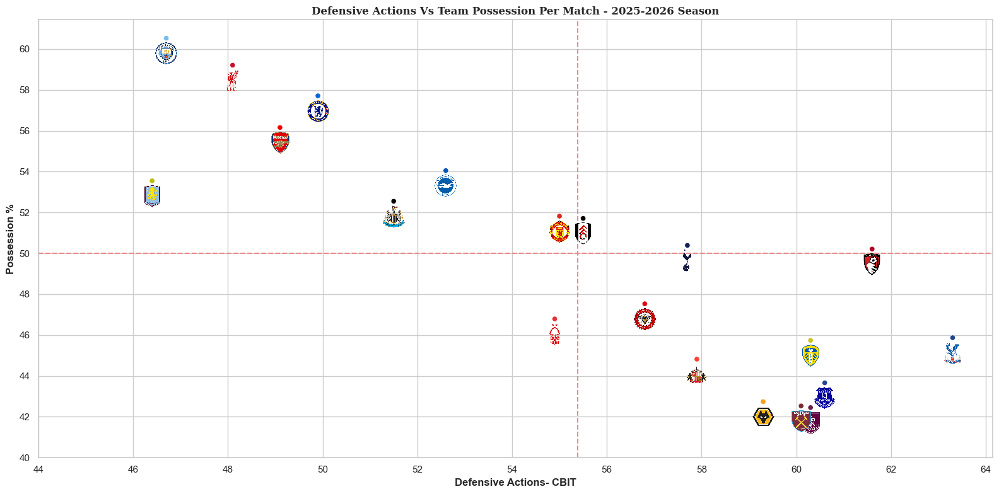

In [21]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(16, 8))

sns.scatterplot(x="sum_def_cont", y="possession", data= df_poss, hue= 'team_shortname', palette= pl_team_colors_25_26, ax= ax, legend= False)
plt.xticks(np.arange(44, 65, step= 2))
plt.yticks(np.arange(40, 62, step= 2))

plt.axvline(x =df_poss['sum_def_cont'].mean(), color = "#F08989", linestyle = '--', )
plt.axhline(y =df_poss['possession'].mean(), color = "#F08989", linestyle = '--')


coords = df_poss.set_index("team_shortname")[["sum_def_cont", "possession"]]
xy_map = {k: (v["sum_def_cont"], v["possession"]) for k, v in coords.to_dict("index").items()}

default_offset = (0, -0.75)

for team, (x, y) in xy_map.items():
    dx, dy = default_offset
    logo_pos = (x + dx, y + dy)
    logos.add_logo(ax, team, logo_pos, zoom=0.035)


ax.set_title("Defensive Actions Vs Team Possession Per Match - 2025-2026 Season", fontsize=18, font="serif", weight="bold")
ax.set_xlabel("Defensive Actions- CBIT", weight="bold")
ax.set_ylabel("Possession %", weight="bold")

fig.tight_layout()


